# Assignment 2510

#### Abdalrahman Mohammed & Casper Aborres

### Project A: Enhancing the LSTM-VAE for Time-Series Anomaly Detection

#### Importing Necessary Libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import Input, LSTM, RepeatVector, Dense, Lambda
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras import losses


#### Data Preprocessing and Windowing

The model processes multivariate time-series sensor data from `sample_data.dat`, containing 419 observations across 13 sensor features. The sensor values are already normalized between 0 and 1, which helps improve numerical stability during training.

Since LSTM networks require sequential input, a sliding window approach is used to transform the original two-dimensional data into three-dimensional sequences.

#### Windowed Data Sample

To allow the model to learn temporal patterns, the data is grouped into overlapping windows of three timesteps.

- Sample 1: Contains rows [0, 1, 2].
- Sample 2: Contains rows [1, 2, 3].
- Sample 3: Contains rows [2, 3, 4].
- Final shape: (415, 3, 13).

#### Dataset Splitting

The windowed dataset is divided chronologically into three subsets:

- Training set: 60% — used to train the models.
- Calibration set: 20% — used to establish the anomaly thresholds.
- Test set: 20% — used to evaluate reconstruction performance and compare thresholding methods.

A gap of two sequences is introduced between the subsets to prevent overlapping timesteps and reduce data leakage.

In [2]:
def get_raw_data():
    # 1. Load the binary data and reshape to 13 columns as per Lab1
    data = np.fromfile("data_lab1/sample_data.dat").reshape(419, 13)
    return data

def get_windowed_data(data, timesteps=3):
    # 2. Apply the sliding window logic
    dataX = []
    for i in range(len(data) - timesteps - 1):
        x_window = data[i:(i + timesteps), :]
        dataX.append(x_window)
    return np.array(dataX)

# --- EXECUTION ---
raw_data = get_raw_data()
windowed_data = get_windowed_data(raw_data)

In [3]:
# Create generic headers for the 13 features
headers = [f"Sensor_{i+1}" for i in range(13)]

# A. Show Table (First 5 Rows of the raw data)
print("--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---")
df = pd.DataFrame(raw_data, columns=headers)
print(df.head(5))

# B. Show 5 Samples of Windowed Data (Each sample is 3 timesteps)
print("\n--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---")
for i in range(5):
    print(f"\nSample {i+1} (Shape: {windowed_data[i].shape}):")
    # Displaying each sample as a small dataframe for clarity
    sample_df = pd.DataFrame(windowed_data[i], columns=headers)
    sample_df.index = [f"t-{2-j}" for j in range(3)] # Labeling time steps
    print(sample_df)

--- FIRST 5 ROWS OF RAW DATA (13 FEATURES) ---
   Sensor_1  Sensor_2  Sensor_3  Sensor_4  Sensor_5  Sensor_6  Sensor_7  \
0  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
1  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.285714   
2  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
3  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   
4  0.649313  0.896542   0.27325   0.22933  0.872118  0.142583  0.357143   

   Sensor_8  Sensor_9  Sensor_10  Sensor_11  Sensor_12  Sensor_13  
0  0.318182  0.853846   0.617647   0.293478   0.398936   0.296296  
1  0.318182  0.961538   0.715686   0.344203   0.414894   0.259259  
2  0.369318  1.000000   0.833333   0.449275   0.505319   0.277778  
3  0.477273  0.792308   0.921569   0.507246   0.648936   0.277778  
4  0.517045  0.707692   0.980392   0.489130   0.675532   0.296296  

--- FIRST 5 WINDOWED SAMPLES (FOR LSTM INPUT) ---

Sample 1 (Shape: (3, 13)):
     Sensor_1  

#### Defining the Beta Variational Autoencoder (β-VAE) Architecture

The original LSTM-VAE architecture from Lab 1 is retained and extended by introducing a tunable beta hyperparameter that controls the contribution of the KL divergence to the total loss.

The architecture consists of:

- An LSTM encoder with 32 hidden units.
- Two dense layers representing the latent mean and log variance.
- A 100-dimensional latent space.
- A custom VAELayer implementing the reparameterization trick and beta-weighted KL divergence.
- A RepeatVector layer and LSTM decoder for sequence reconstruction.

The model is constructed using the `build_vae(beta)` function, allowing independent models to be initialized and trained with different beta values.

The total loss is defined as:

$$L_{total} = L_{MSE} + \beta L_{KL}$$

Three beta values are investigated:

- **β = 0.1:** Weaker latent space regularization.
- **β = 1.0:** Standard VAE loss weighting.
- **β = 5.0:** Stronger latent space regularization.

All other architectural parameters remain unchanged from Lab 1 to ensure a consistent comparison.

In [4]:
class VAELayer(layers.Layer):
    def __init__(self, beta=1.0, **kwargs):
        super(VAELayer, self).__init__(**kwargs)
        self.beta = beta

    def call(self, inputs):
        z_mean, z_log_sigma = inputs

        # Calculate and add weighted KL divergence
        kl_loss = -0.5 * tf.reduce_mean(1 + z_log_sigma - tf.square(z_mean)- tf.exp(z_log_sigma))
        self.add_loss(self.beta * kl_loss)

        # Reparameterization trick
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(z_log_sigma / 2) * epsilon


# Model parameters
intermediate_dim = 32
latent_dim = 100
batch_size = 1
timesteps = 3
input_dim = 13
beta = 1.0
# --- ENCODER ---
inputs = layers.Input(shape=(timesteps, input_dim))
h = layers.LSTM(intermediate_dim)(inputs)
z_mean = layers.Dense(latent_dim)(h)
z_log_sigma = layers.Dense(latent_dim)(h)

# Sample latent vector and add weighted KL loss
z = VAELayer(beta=beta)([z_mean, z_log_sigma])

# --- DECODER ---
decoder_h = layers.LSTM(intermediate_dim, return_sequences=True)
decoder_mean = layers.LSTM(input_dim, return_sequences=True)

h_decoded = layers.RepeatVector(timesteps)(z)
h_decoded = decoder_h(h_decoded)
x_decoded_mean = decoder_mean(h_decoded)

# --- MODEL ---
vae = models.Model(inputs, x_decoded_mean)

# Use MSE loss and track reconstruction error (KL is added by VAELayer)
vae.compile(optimizer="adam", loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="reconstruction_mse")])

# For Inference: Encoder and Generator
encoder = models.Model(inputs, [z_mean, z_log_sigma])

decoder_input = layers.Input(shape=(latent_dim,))
_h_decoded = layers.RepeatVector(timesteps)(decoder_input)
_h_decoded = decoder_h(_h_decoded)
_x_decoded_mean = decoder_mean(_h_decoded)
generator = models.Model(decoder_input, _x_decoded_mean)


print("Model built and compiled successfully.")



Model built and compiled successfully.


In [5]:
vae.summary()

# Encoder summary
encoder.summary()

# Generator (decoder) summary
generator.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3, 13)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │      5,888 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 100)       │      3,300 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 100)       │      3,300 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vae_layer           │ (None, 100)       │          0 │ dense[0][0],      │
│ (VAELayer)          │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 3, 100)    │          0 │ vae_layer[0][0]   │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 3, 32)     │     17,024 │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 3, 13)     │      2,392 │ lstm_1[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,904 (124.62 KB)

 Trainable params: 31,904 (124.62 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_1"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 3, 100)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 3, 32)          │        17,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 3, 13)          │         2,392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,416 (75.84 KB)

 Trainable params: 19,416 (75.84 KB)

 Non-trainable params: 0 (0.00 B)

### Training

In [7]:
beta_values = [0.1, 1.0, 5.0]

results = []
histories = {}
predictions = {}
errors = {}

# Split the dataset chronologically
x = windowed_data.astype("float32")
split1 = int(len(x) * 0.6)
split2 = int(len(x) * 0.8)

# Avoid overlapping timesteps between splits
gap = timesteps - 1
x_train = x[:split1]
x_cal = x[split1 + gap:split2]
x_test = x[split2 + gap:]

print("Training data:", x_train.shape)
print("Calibration data:", x_cal.shape)
print("Testing data:", x_test.shape)


for beta in beta_values:

    print(f"\nTraining model with beta = {beta}")
    tf.keras.utils.set_random_seed(42)

    # --- ENCODER ---
    inputs = layers.Input(shape=(timesteps, input_dim))
    h = layers.LSTM(intermediate_dim)(inputs)
    z_mean = layers.Dense(latent_dim)(h)
    z_log_sigma = layers.Dense(latent_dim)(h)

    # Sample latent vector and add weighted KL loss
    z = VAELayer(beta=beta)([z_mean, z_log_sigma])

    # --- DECODER ---
    decoder_h = layers.LSTM(intermediate_dim, return_sequences=True)
    decoder_mean = layers.LSTM(input_dim, return_sequences=True)

    h_decoded = layers.RepeatVector(timesteps)(z)
    h_decoded = decoder_h(h_decoded)
    x_decoded_mean = decoder_mean(h_decoded)

    # --- MODEL ---
    vae = models.Model(inputs, x_decoded_mean)

    # Use MSE loss and track reconstruction error (KL is added by VAELayer)
    vae.compile(optimizer="adam", loss="mse", metrics=[tf.keras.metrics.MeanSquaredError(name="reconstruction_mse")])

    # For Inference: Encoder and Generator
    encoder = models.Model(inputs, [z_mean, z_log_sigma])

    decoder_input = layers.Input(shape=(latent_dim,))
    _h_decoded = layers.RepeatVector(timesteps)(decoder_input)
    _h_decoded = decoder_h(_h_decoded)
    _x_decoded_mean = decoder_mean(_h_decoded)
    generator = models.Model(decoder_input, _x_decoded_mean)

    # --- TRAINING ---
    history = vae.fit(x_train, x_train, epochs=20, batch_size=batch_size, verbose=1)
    histories[beta] = history.history

    # Get latent parameters for test data
    z_mean, z_log_sigma = encoder.predict(x_test, verbose=0)

    # Reconstruct using the latent mean
    preds = generator.predict(z_mean, verbose=0)

    # Calculate reconstruction MSE
    mse_error = np.mean(np.square(x_test - preds), axis=(1, 2))
    mse = np.mean(mse_error)

    # Calculate unweighted KL divergence
    kl_loss = -0.5 * np.mean(1 + z_log_sigma - np.square(z_mean) - np.exp(z_log_sigma))

    # Calibration reconstruction errors
    z_cal, _ = encoder.predict(x_cal, verbose=0)
    cal_preds = generator.predict(z_cal, verbose=0)
    cal_errors = np.mean(np.square(x_cal - cal_preds), axis=(1, 2))

    # Store results
    predictions[beta] = preds
    errors[beta] = {"calibration": cal_errors, "test": mse_error}
    results.append({"Beta": beta, "Reconstruction MSE": mse, "KL Loss": kl_loss})

# Display results
results_df = pd.DataFrame(results)
display(results_df)

Training data: (249, 3, 13)
Calibration data: (81, 3, 13)
Testing data: (81, 3, 13)

Training model with beta = 0.1
Epoch 1/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.1122 - reconstruction_mse: 0.1009
Epoch 2/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0446 - reconstruction_mse: 0.0355
Epoch 3/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0376 - reconstruction_mse: 0.0303
Epoch 4/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0324 - reconstruction_mse: 0.0241
Epoch 5/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0283 - reconstruction_mse: 0.0203
Epoch 6/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0269 - reconstruction_mse: 0.0198
Epoch 7/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0245 - reconstruction_mse: 0.0184
Epoch 8/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0239 - reconstruction_mse: 0.0186
Epoch 9/20
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0235 - reconstruction_mse: 0.0179
Epoch 10/20
249/249 

,Beta,Reconstruction MSE,KL Loss
0,0.1,0.017911,0.051057
1,1.0,0.024992,0.007405
2,5.0,0.045768,0.000030


## Evaluation and Anomaly Detection

### Reconstruction Error

The reconstruction error is calculated using Mean Squared
Error (MSE) between the original and reconstructed sequences.
Higher reconstruction errors indicate potentially anomalous
behaviour.

### Static Percentile Thresholding

The static threshold is calculated using the 90th percentile
of reconstruction errors from the calibration dataset.

It remains constant throughout the evaluation.

### Dynamic Moving Window Thresholding

The dynamic threshold is calculated using the rolling mean
and standard deviation of the previous 30 reconstruction
errors.

A sensitivity multiplier of k = 3 is used.

The current reconstruction error is excluded from its own
threshold calculation to prevent information leakage.

Both thresholding methods are evaluated on the same test
dataset for each beta value.


Beta = 0.1
Static threshold: 0.046821
Static anomalies: 0
Dynamic anomalies: 2


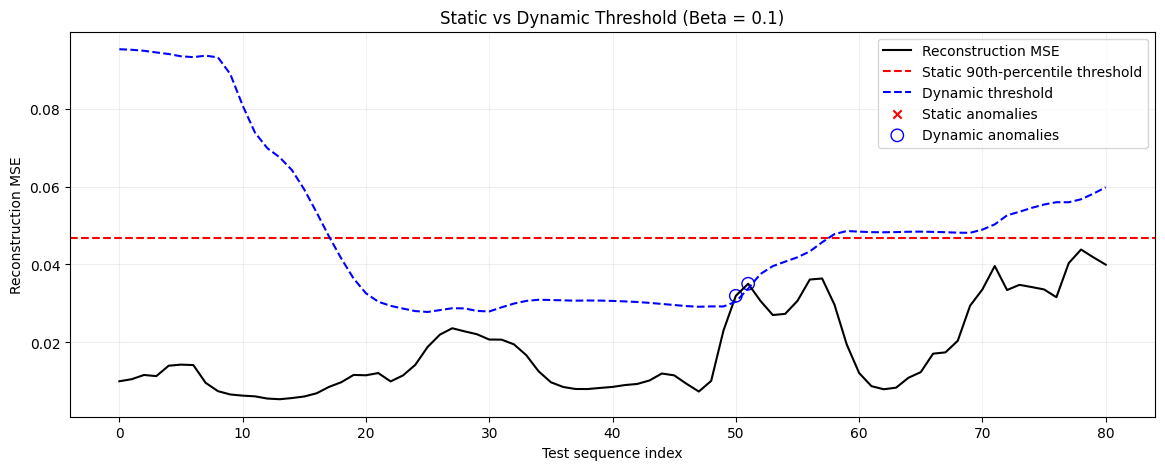


Beta = 1.0
Static threshold: 0.052640
Static anomalies: 4
Dynamic anomalies: 0


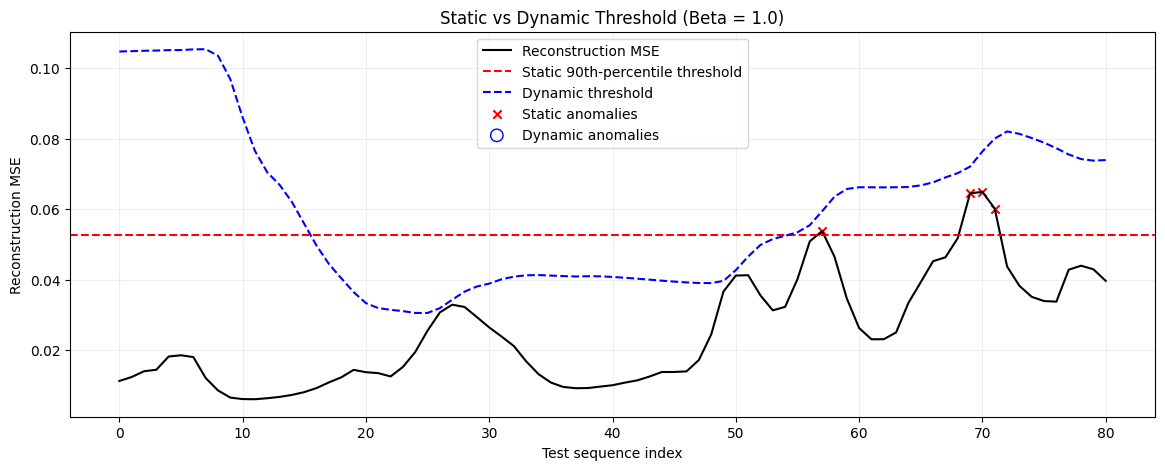


Beta = 5.0
Static threshold: 0.061838
Static anomalies: 18
Dynamic anomalies: 4


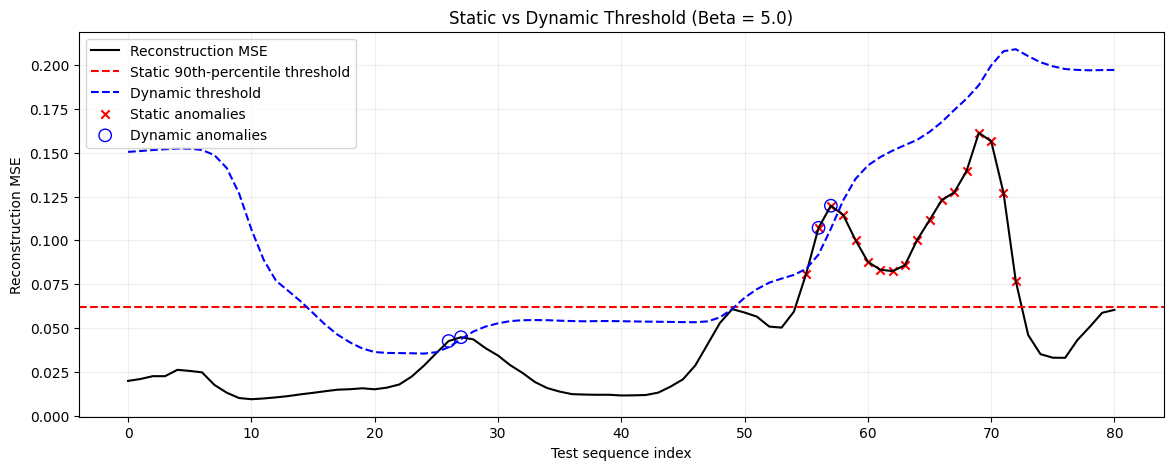

,Beta,Static anomalies,Dynamic anomalies
0,0.1,0,2
1,1.0,4,0
2,5.0,18,4


In [8]:

# Dynamic threshold parameters
window_size = 30
k = 3

threshold_results = []

for beta in beta_values:

    cal_errors = errors[beta]["calibration"]
    mse_error = errors[beta]["test"]

    # Identifying the top 10% highest errors as potential anomalies
    static_threshold = np.percentile(cal_errors, 90)
    static_anomalies = mse_error > static_threshold

    # Combine previous and current reconstruction errors
    error_series = pd.Series(np.concatenate([cal_errors, mse_error]))

    # Calculate rolling statistics using previous errors
    rolling_mean = error_series.shift(1).rolling(window=window_size).mean()
    rolling_std = error_series.shift(1).rolling(window=window_size).std()

    # Calculate dynamic threshold
    dynamic_threshold = rolling_mean + k * rolling_std

    # Keep only thresholds corresponding to test data
    dynamic_threshold = dynamic_threshold.iloc[len(cal_errors):].to_numpy()

    # Detect anomalies
    dynamic_anomalies = mse_error > dynamic_threshold

    print(f"\nBeta = {beta}")
    print(f"Static threshold: {static_threshold:.6f}")
    print("Static anomalies:", np.sum(static_anomalies))
    print("Dynamic anomalies:", np.sum(dynamic_anomalies))

    threshold_results.append({"Beta": beta, "Static anomalies": np.sum(static_anomalies), "Dynamic anomalies": np.sum(dynamic_anomalies)})

    # --- PLOT COMPARISON ---
    plt.figure(figsize=(14, 5))
    plt.plot(mse_error, color="black", label="Reconstruction MSE")
    plt.axhline(y=static_threshold, color="red", linestyle="--", label="Static 90th-percentile threshold")
    plt.plot(dynamic_threshold, color="blue", linestyle="--", label="Dynamic threshold")

    static_idx = np.where(static_anomalies)[0]
    dynamic_idx = np.where(dynamic_anomalies)[0]

    plt.scatter(static_idx, mse_error[static_idx], color="red", marker="x", label="Static anomalies")
    plt.scatter(dynamic_idx,mse_error[dynamic_idx],color="blue", facecolors="none", s=80, label="Dynamic anomalies")

    plt.title(f"Static vs Dynamic Threshold (Beta = {beta})")
    plt.xlabel("Test sequence index")
    plt.ylabel("Reconstruction MSE")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


display(pd.DataFrame(threshold_results))


Plot reconstruction MSE vs. KL loss


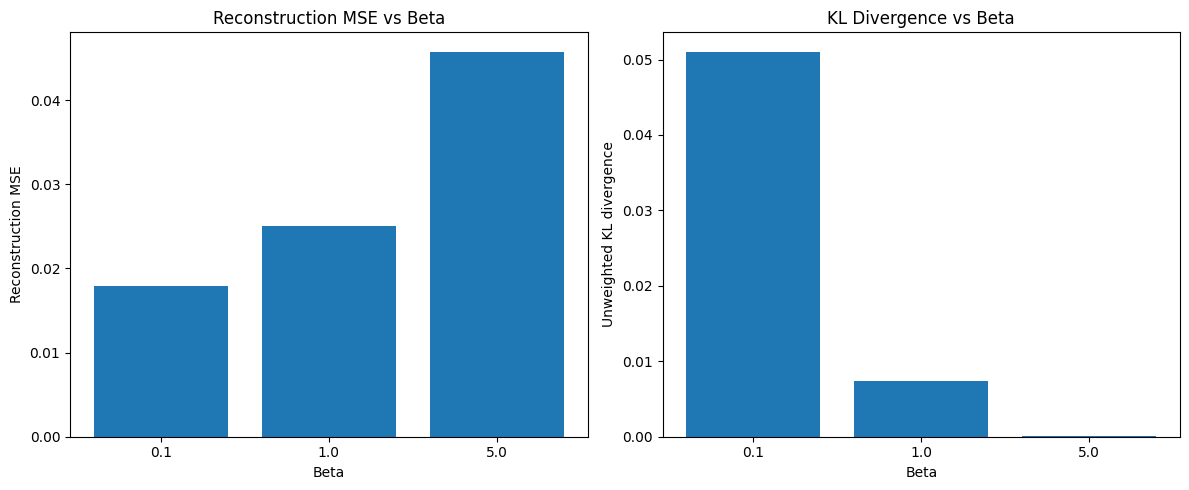

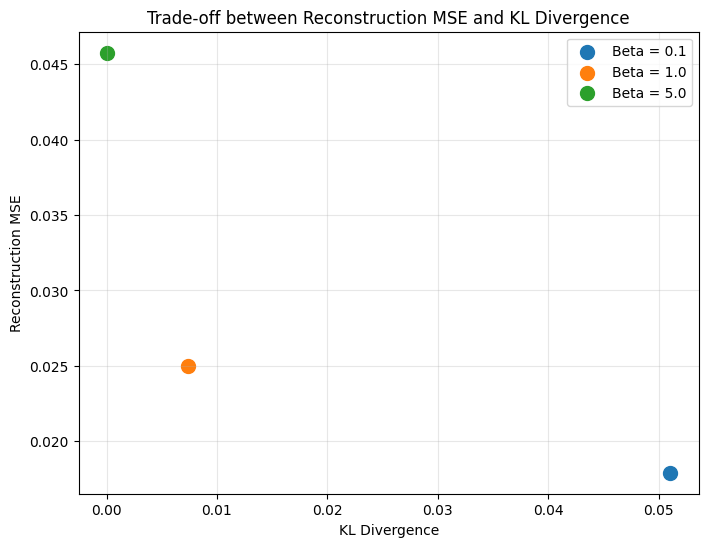

,Beta,Reconstruction MSE,KL Loss
0,0.1,0.017911,0.051057
1,1.0,0.024992,0.007405
2,5.0,0.045768,0.000030


In [14]:

# Compare reconstruction MSE and KL loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
beta_labels = results_df["Beta"].astype(str)

# Reconstruction MSE
ax1.bar(beta_labels,results_df["Reconstruction MSE"])
ax1.set_title("Reconstruction MSE vs Beta")
ax1.set_xlabel("Beta")
ax1.set_ylabel("Reconstruction MSE")

# KL divergence
ax2.bar(beta_labels, results_df["KL Loss"])
ax2.set_title("KL Divergence vs Beta")
ax2.set_xlabel("Beta")
ax2.set_ylabel("Unweighted KL divergence")

plt.tight_layout()
plt.show()


# Direct comparison of MSE against KL divergence
plt.figure(figsize=(8, 6))

for _, row in results_df.iterrows():
    plt.scatter(row["KL Loss"], row["Reconstruction MSE"], s=100, label=f'Beta = {row["Beta"]}')

plt.xlabel("KL Divergence")
plt.ylabel("Reconstruction MSE")
plt.title("Trade-off between Reconstruction MSE and KL Divergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

display(results_df)


Plot the training progress

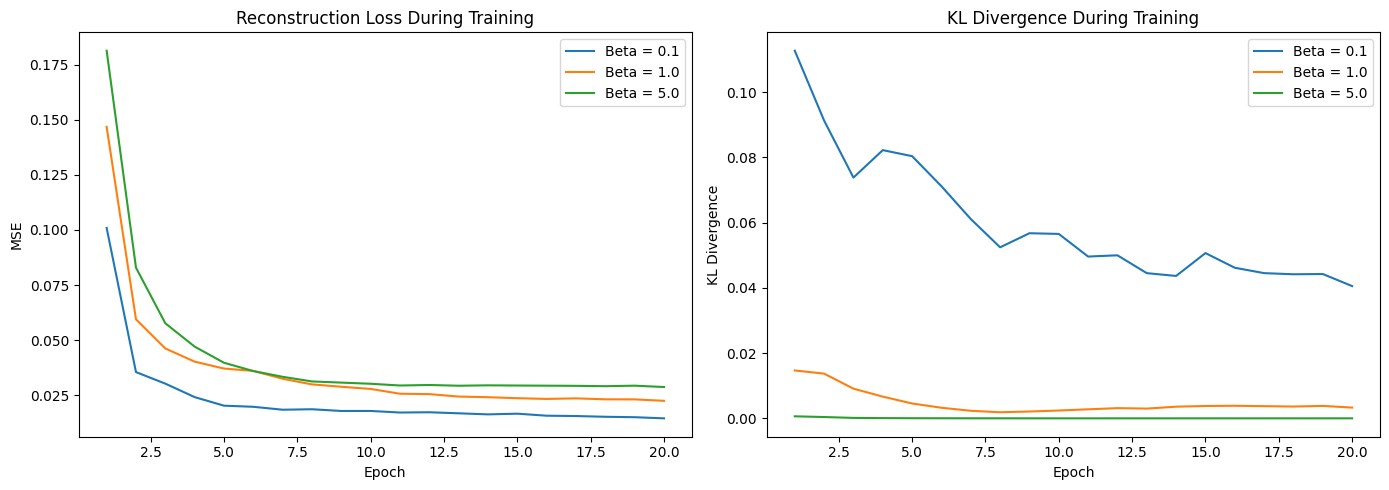

In [15]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for beta in beta_values:

    history = histories[beta]
    reconstruction_loss = np.array(history["reconstruction_mse"])
    total_loss = np.array(history["loss"])

    # Extract unweighted KL from total loss
    kl_loss = (total_loss - reconstruction_loss) / beta

    epochs_range = range(1, len(total_loss) + 1)

    ax1.plot(epochs_range, reconstruction_loss, label=f"Beta = {beta}")
    ax2.plot(epochs_range, kl_loss, label=f"Beta = {beta}" )

ax1.set_title("Reconstruction Loss During Training")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE")
ax1.legend()

ax2.set_title("KL Divergence During Training")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("KL Divergence")
ax2.legend()

plt.tight_layout()
plt.show()
